### **STUDENT PERFORMANCE INDICATOR**

#### **LIFE CYCLE OF Machine Learning Project** 
- Understanding the Problem Statement
- Data Collection
- Data Checks to perform
- Exploratory Data Analysis
- Data Pre-Processing
- Model Training 
- Choose Best Model

#### **1. PROBLEM STATEMENT:**

- The problem understands how the student's performance (Test Scores) is affected by other variables such as Gender, Ethnicity, Parental level of Education, Lunch and Test Preparation course.

#### **2. DATA COLLECTION:**

- Dataset Source: "https://www.kaggle.com/datasets/sandeepgauti/student-performance-data?resource=download"
- The Data consists of 8 Columns and 1000 Rows.

---
#### **IMPORT DATA AND REQUIRED PACKAGES**

**IMPORTING PANDAS, NUMPY, MATPLOTLIB, SEABORN & WARINGS Library:**

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

---
**IMPORT THE CSV DATA as PANDAS DATAFRAME**

In [2]:
df = pd.read_csv('notebook/data/stud.csv')
df.head()   # Shows the Top 5 Records

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


---
**SHAPE OF THE DATASET**

In [3]:
df.shape

(1000, 8)

---
#### **3. DATASET INFORMATION:**

- Gender: Sex of the Students -> (Male / Female)
- Race / Ethnicity: Ethnicity of the Students -> (Group A, B, C, D, E)
- Parental Level of Education: Parent's Final Education -> (Bachelor's Degree; Some College; Master's Degree; Associate's Degree; High School)
- Lunch: Having lunch before Test (Standard or Free/Reduced)
- Test Preparation Course: Complete or Not Complete before the Test
- Math Score
- Reading Score
- Writing Score

---
**DATA CHECKS TO PERFORM:**

1) Check for Missing Values
2) Check Duplicates
3) Check Data Type
4) Check the Number of Unique Values in each coulumns
5) Check the Statistics of Data Set
6) Check various categories present in the Different Categorical Column

---
**A. CHECK FOR MISSING VALUES:**

In [4]:
df.isna().sum()

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

###### **THERE IS NO MISSING VALUES IN THE DATASET**

---
**B. CHECK FOR DUPLICATES IN THE DATASET:**

In [5]:
df.duplicated().sum()

0

###### **NO DUPLICATE VALUES IN THE DATASET**

---
**C. CHECK FOR DATA TYPES:**

In [6]:
# Check for Null and Dtypes:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race_ethnicity               1000 non-null   object
 2   parental_level_of_education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test_preparation_course      1000 non-null   object
 5   math_score                   1000 non-null   int64 
 6   reading_score                1000 non-null   int64 
 7   writing_score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


---
**D. CHECKING THE NUMBER OF UNIQUE VALUES OF EACH COLUMNS:**

In [7]:
df.nunique()

gender                          2
race_ethnicity                  5
parental_level_of_education     6
lunch                           2
test_preparation_course         2
math_score                     81
reading_score                  72
writing_score                  77
dtype: int64

---
**E. CHECK STATISTICS OF DATASET:**

In [8]:
df.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


**INSIGHT:**
- From the above description of Numerical Data, all `Means` are `very close` to each other i.e., between `66` & `68.05`.
- All `Standard Deviations` are also `close` - between `14.6` & `15.19`.
- While there is `minimum score` of 0 for Maths, for Writing minimum is much higher i.e., 10 and for Reading most higher i.e., 17

---
**F. EXPLORING DATA:**

In [9]:
print("1. Categories in 'Gender' Variable: ", end = " ")
print(df['gender'].unique())

print("2. Categories in 'Race & Ethnicity' Variable: ", end = " ")
print(df['race_ethnicity'].unique())

print("3. Categories in 'Parental Education' Variable: ", end = " ")
print(df['parental_level_of_education'].unique())

print("4. Categories in 'Lunch' Variable: ", end = " ")
print(df['lunch'].unique())

print("5. Categories in 'Test Preparation Course' Variable: ", end = " ")
print(df['test_preparation_course'].unique())


1. Categories in 'Gender' Variable:  ['female' 'male']
2. Categories in 'Race & Ethnicity' Variable:  ['group B' 'group C' 'group A' 'group D' 'group E']
3. Categories in 'Parental Education' Variable:  ["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school']
4. Categories in 'Lunch' Variable:  ['standard' 'free/reduced']
5. Categories in 'Test Preparation Course' Variable:  ['none' 'completed']


---
**DEFINING NUMERICAL AND CATEGORICAL FEATURES:**

In [10]:
df.dtypes

gender                         object
race_ethnicity                 object
parental_level_of_education    object
lunch                          object
test_preparation_course        object
math_score                      int64
reading_score                   int64
writing_score                   int64
dtype: object

In [11]:
numerical_features = [feature for feature in df.columns if df[feature].dtype != 'O']
categorical_features = [feature for feature in df.columns if df[feature].dtype == 'O']

print("We have {} Numerical Features: {}".format(len(numerical_features), numerical_features))
print("We have {} Categorical Features: {}".format(len(categorical_features), categorical_features))

We have 3 Numerical Features: ['math_score', 'reading_score', 'writing_score']
We have 5 Categorical Features: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']


---
**ADDING COLUMNS FOR "TOTAL SCORE" & "AVERAGE":**

In [12]:
df['total_score'] = df['math_score'] + df['reading_score'] + df['writing_score']
df['average'] = round(df['total_score'] / 3, 2)
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.67
1,female,group C,some college,standard,completed,69,90,88,247,82.33
2,female,group B,master's degree,standard,none,90,95,93,278,92.67
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.33
4,male,group C,some college,standard,none,76,78,75,229,76.33


---
**FINDING THE NUMBER OF STUDENTS SCORING FULL MARKS**

In [13]:
reading_full = df[df['reading_score'] == 100]['average'].count()
writing_full = df[df['writing_score'] == 100]['average'].count()
math_full = df[df['math_score'] == 100]['average'].count()

print(
    f"Number of Students with Full Marks in Maths: {math_full}\n"
    f"Number of Students with Full Marks in Writing: {writing_full}\n"
    f"Number of Students with Full Marks in Reading: {reading_full}"
)

Number of Students with Full Marks in Maths: 7
Number of Students with Full Marks in Writing: 14
Number of Students with Full Marks in Reading: 17


---
**FINDING THE NUMBER OF STUDENTS SCORING <= 20 MARKS**

In [14]:
reading_less_20 = df[df['reading_score'] <= 20]['average'].count()
writing_less_20 = df[df['writing_score'] <= 20]['average'].count()
math_less_20 = df[df['math_score'] <= 20]['average'].count()

print(
    f"Number of Students with Less than 20 Marks in Maths: {math_less_20}\n"
    f"Number of Students with Less than 20 Marks in Writing: {writing_less_20}\n"
    f"Number of Students with Less than 20 Marks in Reading: {reading_less_20}"
)

Number of Students with Less than 20 Marks in Maths: 4
Number of Students with Less than 20 Marks in Writing: 3
Number of Students with Less than 20 Marks in Reading: 1


**INSIGHTS**

- From the Above Values the Students have Performed the worst in Maths.
- Best Performance of the Students is in Reading Section.

---
#### **4. EXPLORING DATA (VISUALIZATION)**

**A. VISUALIZE AVERAGE SCORE DISTRIBUTION TO MAKE SOME CONCLUSION**

- HISTOGRAM
- KERNEL DISTRIBUTION FUNCTION (KDE)

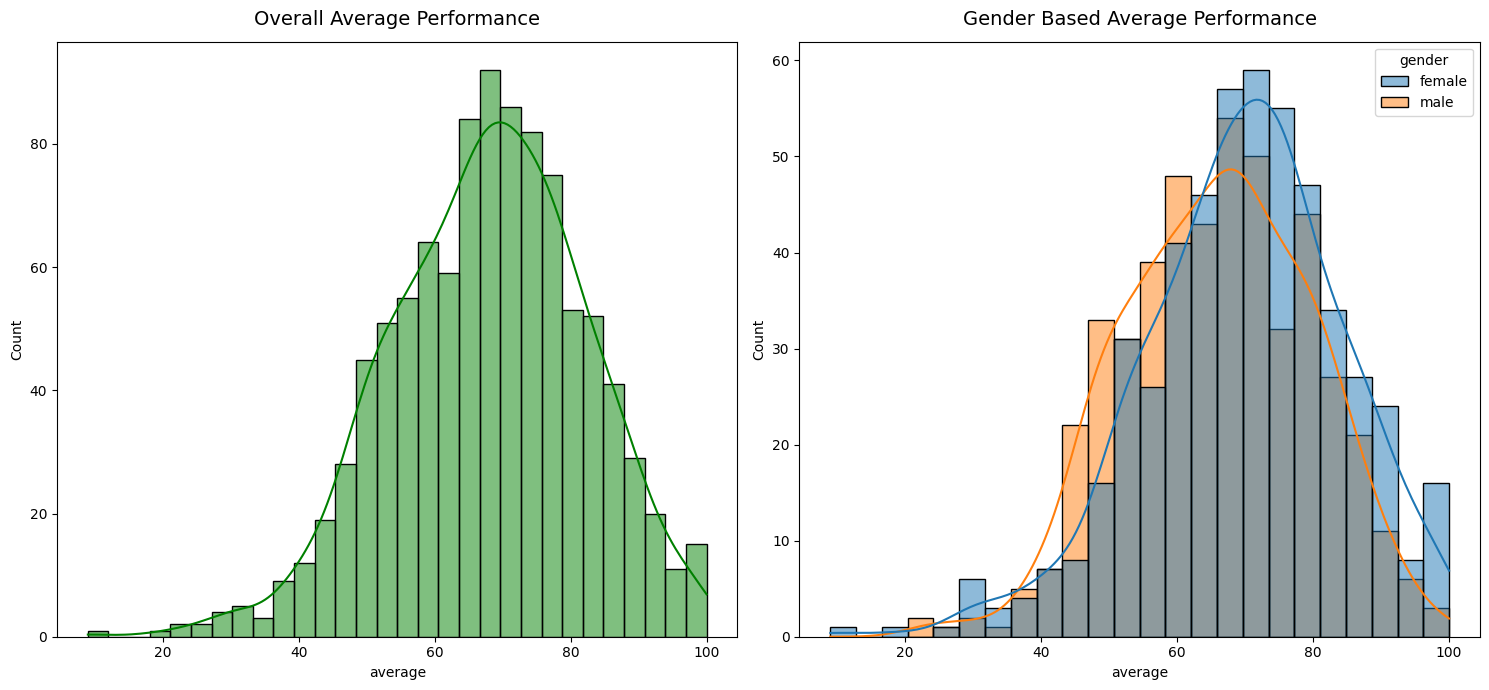

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))

# First Overall Plot
sns.histplot(data=df, x='average', bins=30, kde=True, color='g', ax=axs[0])
axs[0].set_title("Overall Average Performance", fontsize=14, pad=12)

# Second Plot: Gender Based
sns.histplot(data=df, x='average', kde=True, hue='gender', ax=axs[1])
axs[1].set_title("Gender Based Average Performance", fontsize=14, pad=12)

plt.tight_layout()
plt.show()

**INSIGHTS:**

- Female Students tends to perform well than the Male Students.

---
**B. VISUALIZING AVERAGE PERFORMANCE AMONGST GENDER BASED ON LUNCH:**

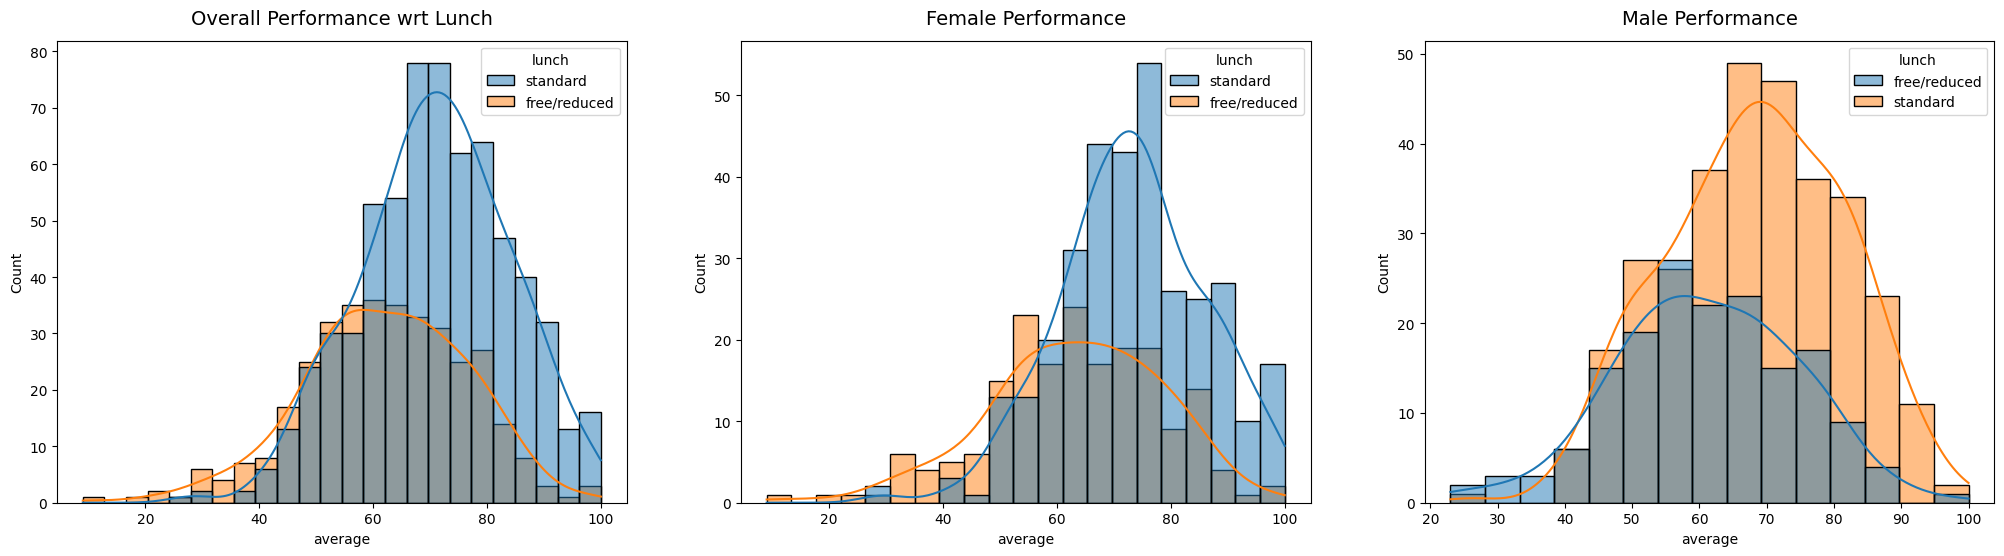

In [16]:
fig, axis = plt.subplots(1, 3, figsize=(25, 6))

# First Overall Plot
sns.histplot(data=df, x='average', kde=True, hue='lunch', ax=axis[0])
axis[0].set_title("Overall Performance wrt Lunch", fontsize=14, pad=12)

# Second Plot: Female
sns.histplot(data=df[df.gender == 'female'], x='average', kde=True, hue='lunch', ax=axis[1])
axis[1].set_title("Female Performance", fontsize=14, pad=12)

# Third Plot: Male
sns.histplot(data=df[df.gender == 'male'], x='average', kde=True, hue='lunch', ax=axis[2])
axis[2].set_title("Male Performance", fontsize=14, pad=12)

plt.show()

**INSIGHTS:**
- Standard Lunch helps perform well in exams.
- Standard Lunch helps perform well in exams be it Male or Female.

---
**C. VISUALIZING AVERAGE PERFORMANCE BASED ON RACE & ETHINICITY:**

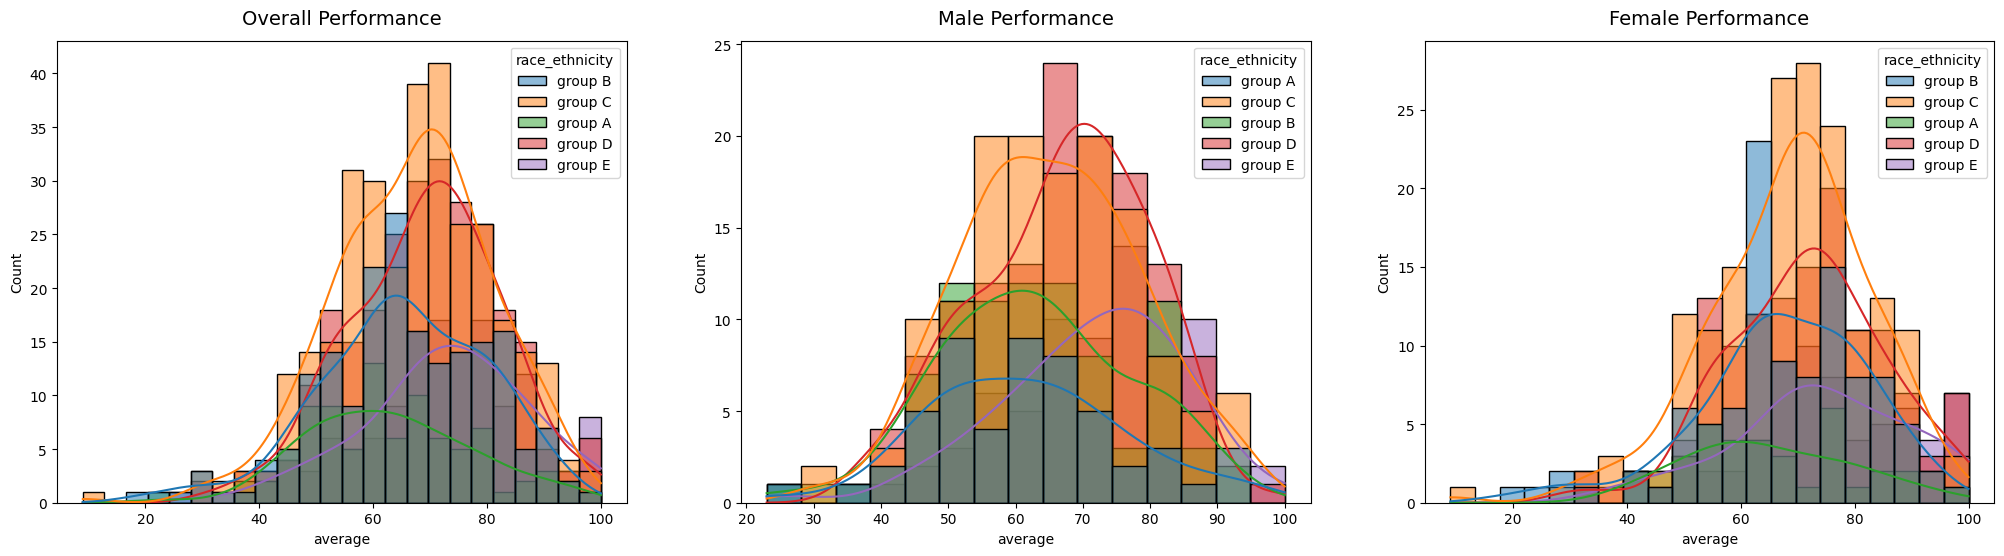

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(25, 6))

# First Overall Plot
sns.histplot(data=df, x='average', kde=True, hue='race_ethnicity', ax=axes[0])
axes[0].set_title("Overall Performance", fontsize=14, pad=12)

# Second Plot: Male
sns.histplot(data=df[df.gender == 'male'], x='average', kde=True, hue='race_ethnicity', ax=axes[1])
axes[1].set_title("Male Performance", fontsize=14, pad=12)

# Third Plot: Female
sns.histplot(data=df[df.gender == 'female'], x='average', kde=True, hue='race_ethnicity', ax=axes[2])
axes[2].set_title("Female Performance", fontsize=14, pad=12)

plt.show()

**INSIGHTS:**
- Students of Group A & Group B -> Tends to perform Poorly in Exams.
- Students of Group A & Group B -> Tends to perform Poorly in Exams irrespective of Gender.

---
**D. VISUALIZING AVERAGE PERFORMANCE BASED ON PARENTAL EDUCATION:**

Text(0.5, 1.0, 'Male Performance based on Parental Education')

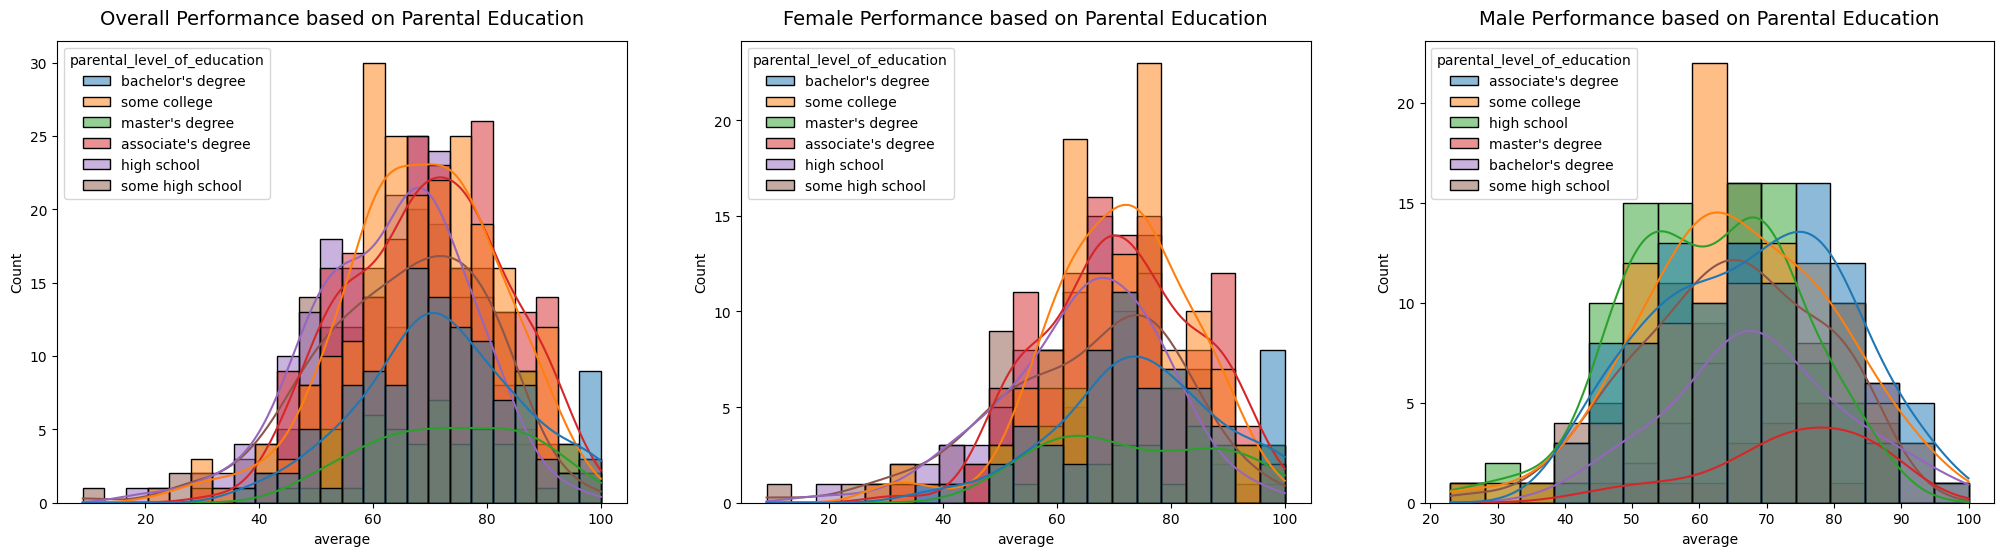

In [18]:
fig, axis = plt.subplots(1, 3, figsize=(25, 6))

# Overall Performance:
sns.histplot(data=df, x='average', hue='parental_level_of_education', kde=True, ax=axis[0])
axis[0].set_title("Overall Performance based on Parental Education", fontsize=14, pad=12)

# Female Performance:
sns.histplot(data=df[df.gender == 'female'], x='average', kde=True, hue='parental_level_of_education', ax=axis[1])
axis[1].set_title("Female Performance based on Parental Education", fontsize=14, pad=12)

# Male Performance:
sns.histplot(data=df[df.gender == 'male'], x='average', kde=True, hue='parental_level_of_education', ax=axis[2])
axis[2].set_title("Male Performance based on Parental Education", fontsize=14, pad=12)

**INSIGHTS:**
- In general Parental Education don't help Student Perform well in Exam.
- 2nd Plot we can see there is no effect of Parent's Education on Female Students.
- 3rd Plot shows that Parent's whose education is of Associate's degree or Master's degree their Male Child tend to perform well in Exam.

---
**E. MAXIMUM SCORE OF STUDENTS IN ALL THREE SUBJECTS:**

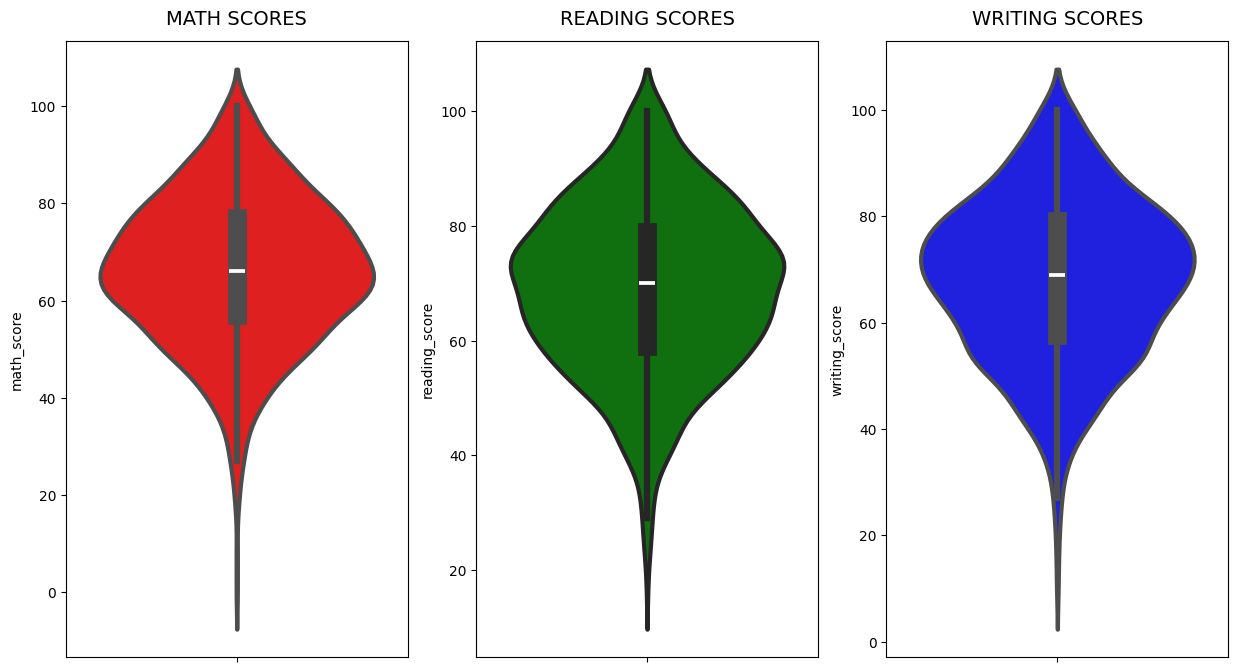

In [19]:
fig, axis = plt.subplots(1, 3, figsize=(15, 8))

sns.violinplot(y='math_score', data=df, color='red', linewidth=3, ax=axis[0])
axis[0].set_title('MATH SCORES', fontsize=14, pad=12)

sns.violinplot(y='reading_score', data=df, color='green', linewidth=3, ax=axis[1])
axis[1].set_title("READING SCORES", fontsize=14, pad=12)

sns.violinplot(y='writing_score', data=df, color='blue', linewidth=3, ax=axis[2])
axis[2].set_title("WRITING SCORES", fontsize=14, pad=12)

plt.show()

**INSIGHTS:**
- From the above Three Plots it is clearly visible that most of the Students score is between 60 - 80 in Maths whereas in Reading and Writing most of them Score between 50 - 80.

---
**F. MULTIVARIATE ANALYSIS USING PIEPLOT:**

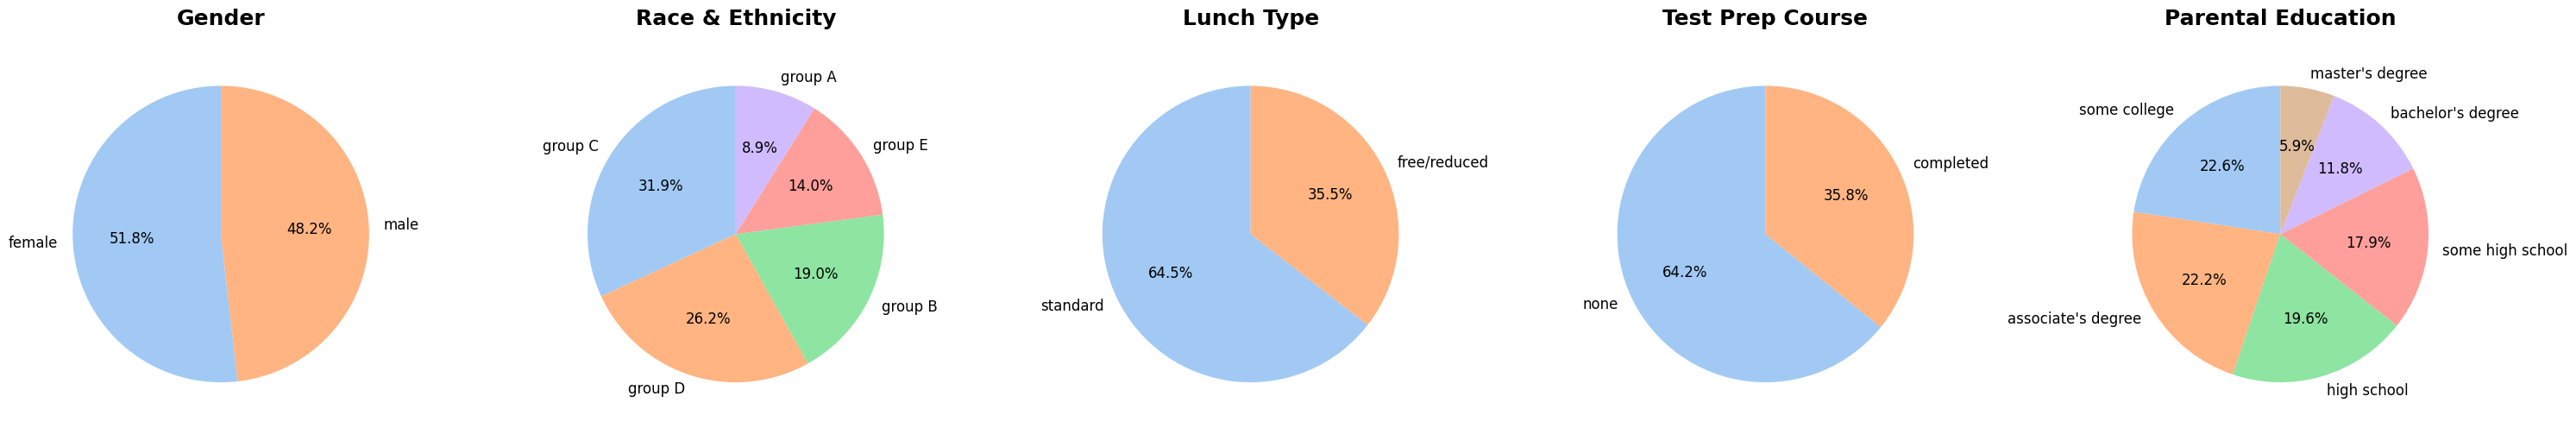

In [20]:
# 1. Define Columns to Plot:
columns = ["gender", "race_ethnicity", "lunch", "test_preparation_course", "parental_level_of_education"]

# 2. Set titles cleanly (instead of relying on strict column names):
titles = ["Gender", "Race & Ethnicity", "Lunch Type", "Test Prep Course", "Parental Education"]

# 3. Create a Modern Color Palette using Seaborn:
colors = sns.color_palette("pastel")

# 4. Initializing the Grid Canvas:
fig, axes = plt.subplots(1, 5, figsize=(30, 10))

# 5. Build Subplots Dynamically:
for i, col in enumerate(columns):
    # Dynamically extract counts and exact matching category names
    counts = df[col].value_counts()
    labels = counts.index

    # Render pie chart directly to the Active Axis Slot
    axes[i].pie(
        counts, labels = labels,
        colors = colors[: len(labels)],
        autopct = "%1.1f%%",  # Percentage layout
        startangle = 90,   # Rotates chart for clean alignment
        textprops = {"fontsize": 12}
    )

    # Set Subplot titles:
    axes[i].set_title(titles[i], fontsize=18, fontweight="bold", pad=20)

# Apply spacing layouts and showcase window:
plt.tight_layout()
plt.show()

**INSIGHTS:**
- Number of Male and Female Students are almost Equal.
- Number of Students are Greatest in Group C.
- Number of Students who have Standard Lunch are Greater.
- Number of Students who have Not Enrolled in any Test Preparation course is Greater.
- Number of Students whose Parental Education is "Some College" is Greater & is followed Closely by "Associate Degree"

---
#### **FEATURE WISE VISUALIZATION:**

**1. GENDER COLUMN:**

- How distributed Gender is?
- Is Gender has any impact on Student's Performance?

**-> UNIVARIATE ANALYSIS (HOW DISTRIBUTED GENDER IS?)**

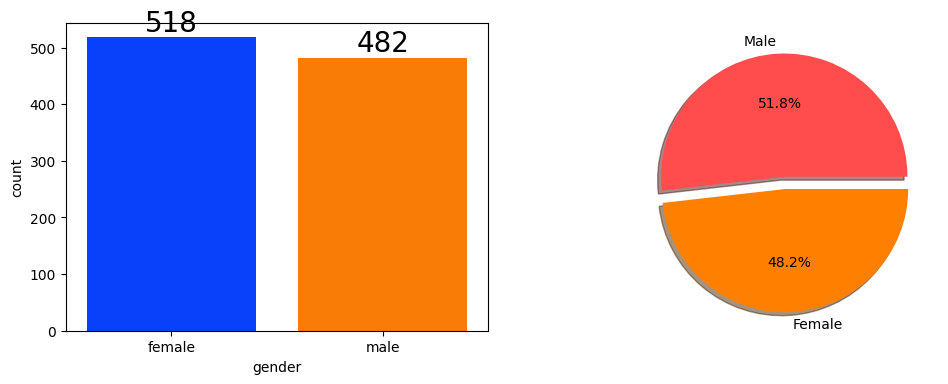

In [21]:
f, ax = plt.subplots(1, 2, figsize = (12, 4))

sns.countplot(data = df, x = df["gender"], palette = "bright", ax = ax[0], saturation = 0.95)
for container in ax[0].containers:
    ax[0].bar_label(container, color = "black", size = 20)

plt.pie(
    x = df['gender'].value_counts(),
    labels = ['Male', "Female"],
    explode = [0, 0.1],
    autopct = "%1.1f%%",
    shadow = True,
    colors = ['#ff4d4d', '#ff8000']
)
plt.show()

---
**-> BIVARIATE ANALYSIS (IS GENDER HAS ANY IMPACT ON STUDENT'S PERFORMANCE)**

In [22]:
gender_grp = df.groupby('gender').mean(numeric_only=True)
gender_grp

,math_score,reading_score,writing_score,total_score,average
gender,,,,,
female,63.633205,72.608108,72.467181,208.708494,69.569498
male,68.728216,65.473029,63.311203,197.512448,65.837303


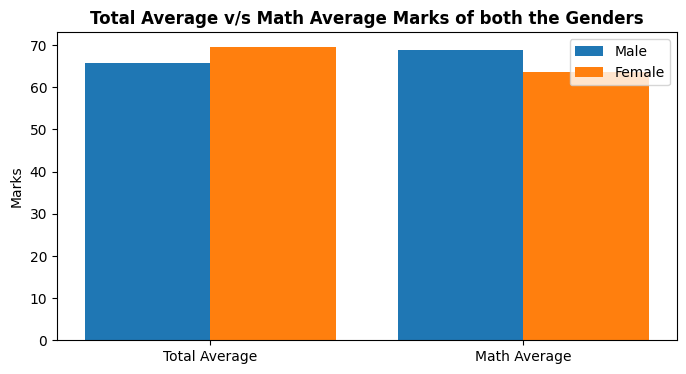

In [23]:
plt.figure(figsize=(8, 4))
X = ['Total Average', 'Math Average']

female_score = [gender_grp['average'][0], gender_grp['math_score'][0]]
male_score = [gender_grp['average'][1], gender_grp['math_score'][1]]

x_axis = np.arange(len(X))

plt.bar(x_axis - 0.2, male_score, 0.4, label = 'Male')
plt.bar(x_axis + 0.2, female_score, 0.4, label = 'Female')

plt.xticks(x_axis, X)
plt.ylabel("Marks")
plt.title("Total Average v/s Math Average Marks of both the Genders", fontweight='bold')
plt.legend()
plt.show()

**INSIGHTS:**

- On an Average Females have a better overall Score than Men.
- Whereas Males have scored higher in Maths.

---
#### **2. RACE & ETNICITY COLUMN:**

- Group wise distribution?
- Is Race / Ethnicity has any impact on Student's Performance?

**--> UNIVARIATE ANALYSIS (GROUP WISE DISTRIBUTION)**

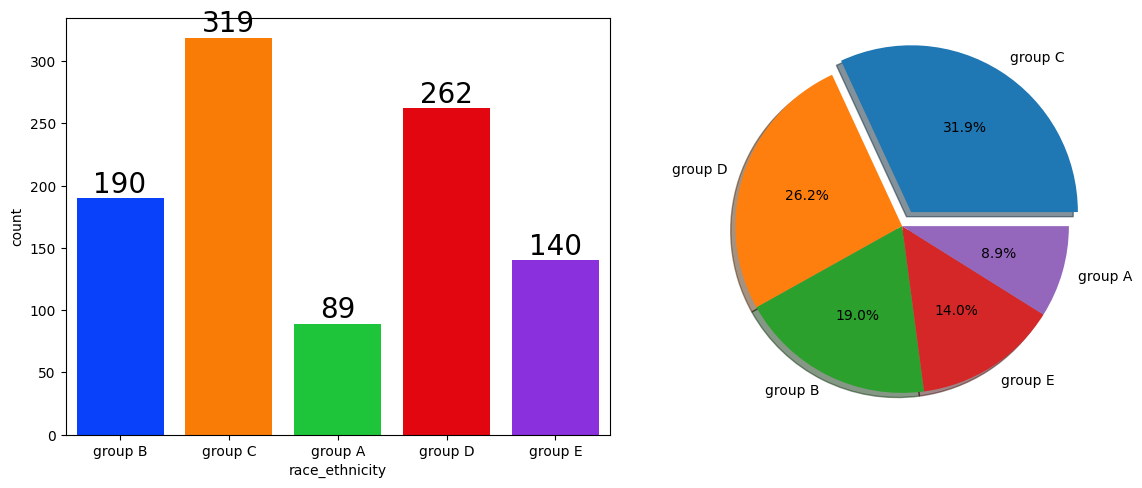

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data = df, x = df['race_ethnicity'], palette = 'bright', ax = axs[0], saturation = 0.95)
for container in axs[0].containers:
    axs[0].bar_label(container, color = 'black', size = 20)

axs[1].pie(
    x = df['race_ethnicity'].value_counts(),
    labels = df['race_ethnicity'].value_counts().index.tolist(),
    autopct = "%1.1f%%",
    explode = [0.1, 0, 0, 0, 0],
    shadow = True
)

plt.tight_layout()
plt.show()

**INSIGHTS:**
- Most of the Students belonging from Group C & Group D.
- Lowest Number of Students belong to Group A.

---
**--> BIVARIATE ANALYSIS (IS RACE OR ETHNICITY HAS ANY IMPACT ON STUDENT'S PEFORMANCE)**

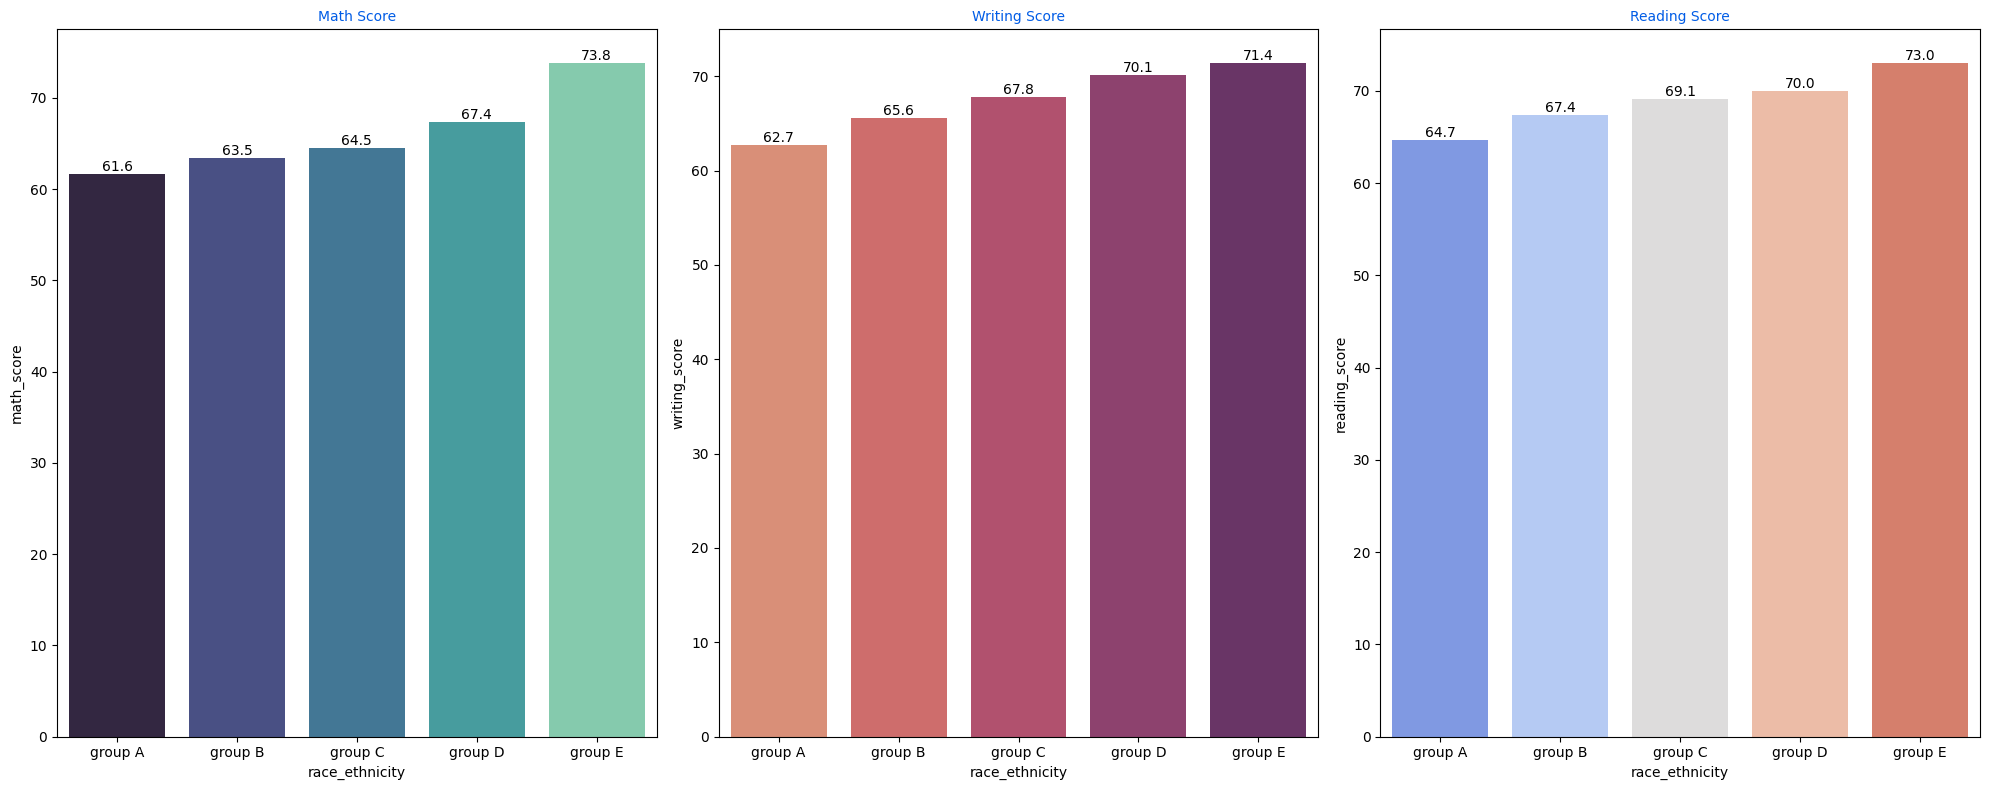

In [25]:
score_plots = [
    ('math_score', 'Math Score', 'mako'),
    ('writing_score', 'Writing Score', 'flare'),
    ('reading_score', 'Reading Score', 'coolwarm')
]
means = df.groupby('race_ethnicity')[[name for name, _, _ in score_plots]].mean()

fig, axes = plt.subplots(1, len(score_plots), figsize=(20, 8))

for ax, (column, title, palette) in zip(axes, score_plots):
    sns.barplot(
        x = means.index,        # group A, group B, group C, ...
        y = means[column],      # bar height = mean score
        palette = palette,      # which set of colors to use
        ax = ax,
        hue = means.index,      # color also follows group A, group B, ...
    )
    ax.set_title(title, color='#005ce6', size=10)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.1f', color='black', size=10)

plt.tight_layout()
plt.show()

**INSIGHTS:**
- Group E Students have scored the Highest Marks.
- Group A Students have scored the Lowest Marks.
- Students from a Lower Socio-Economic Status have a lower average in all course subjects.

---
### **3. PARENTAL LEVEL OF EDUCATION**
- What is the Educational Background of the Student's Parents?
- Is Parental Education has any impact on Student Performance?

**--> UNIVARIATE ANALYSIS (WHAT IS THE EDUCATIONAL BACKGROUND OF STUDENT'S PARENT)**

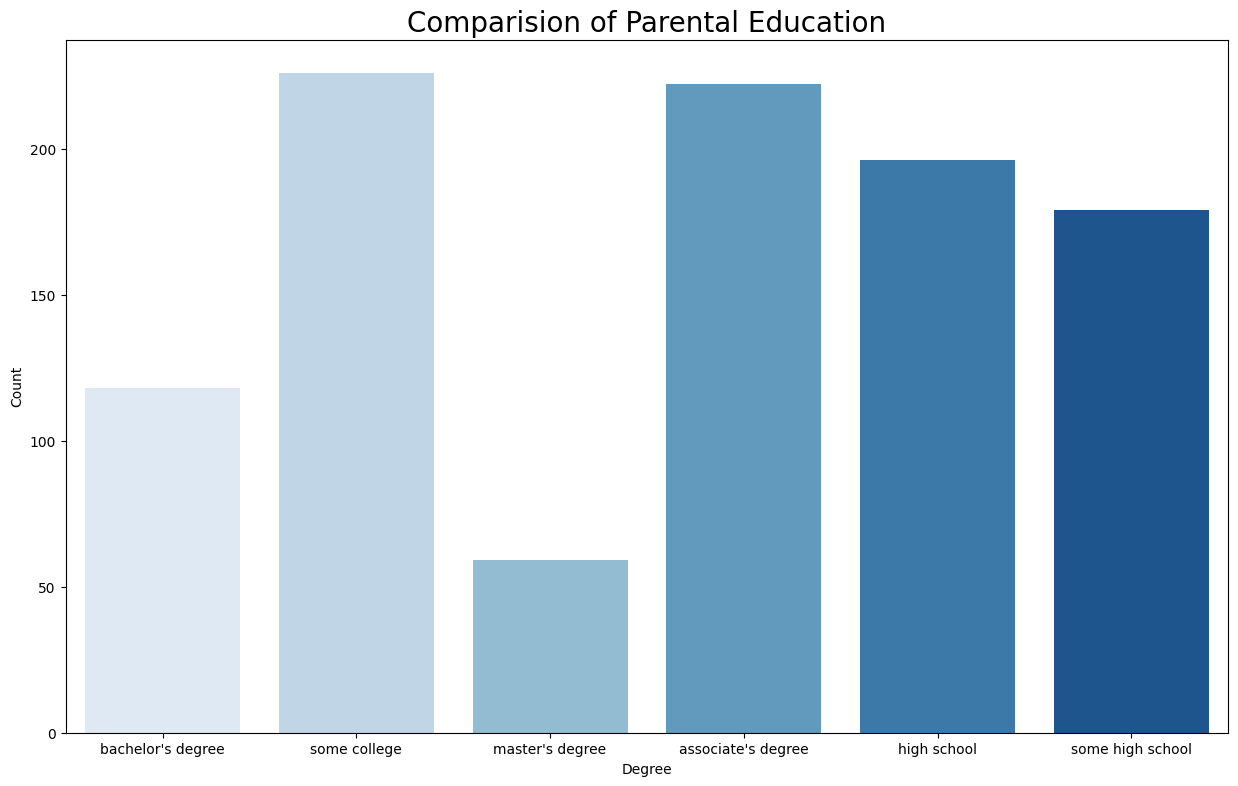

In [26]:
fig = plt.subplots(figsize= (15, 9))

sns.countplot(x = df['parental_level_of_education'], palette = 'Blues')
plt.title('Comparision of Parental Education', fontweight=30, fontsize=20)

plt.xlabel('Degree')
plt.ylabel('Count')
plt.show()

**INSIGHTS:**
- Largest Number of Parents are from Some College.

---
**--> UNIVARIATE ANALYSIS (IS PARENTAL EDUCATION HAS ANY IMPACT ON STUDENTS PERFORMANCE)**

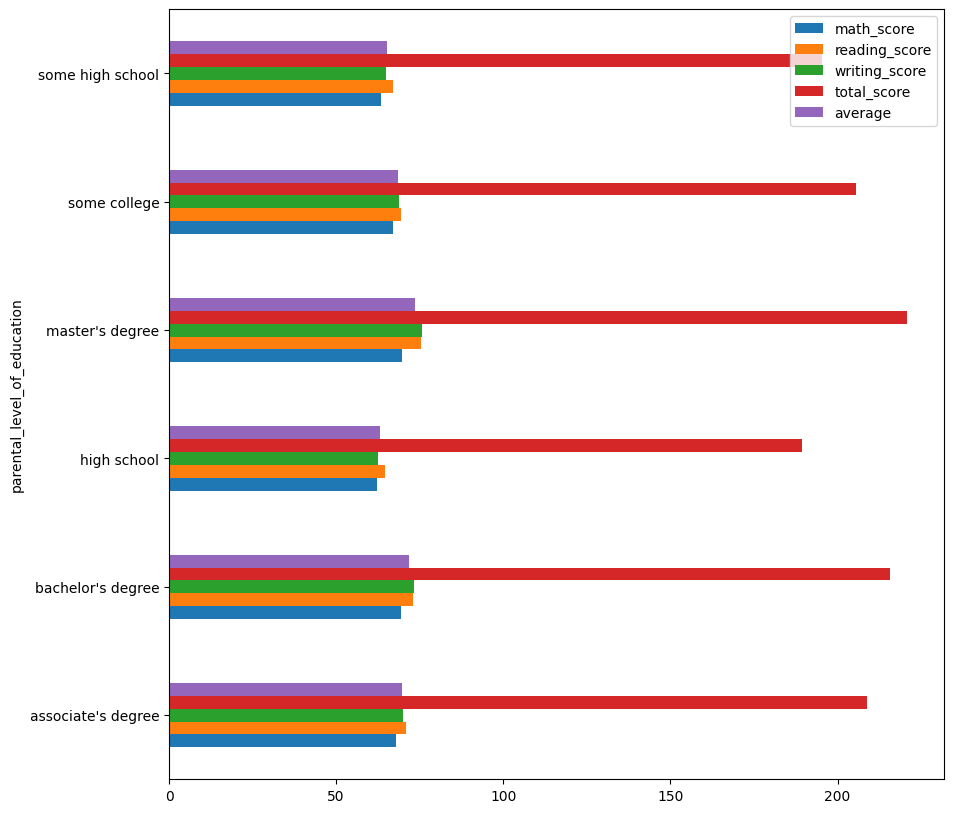

In [27]:
df.groupby('parental_level_of_education').mean(numeric_only=True).plot(kind='barh', figsize=(10,10))
plt.show()

**INSIGHTS:**

- The Score of Students whose Parents possess Master and Bachlor level of Education are higher than others.

---
### **4. LUNCH COLUMN:**
- Which type of Lunch is the most common amongst Students?
- What is the effect of Lunch Type on Test Results?

**--> UNIVARIATE ANALYSIS (WHICH TYPE OF LUNCH IS MOST COMMON AMONGST STUDENTS)**

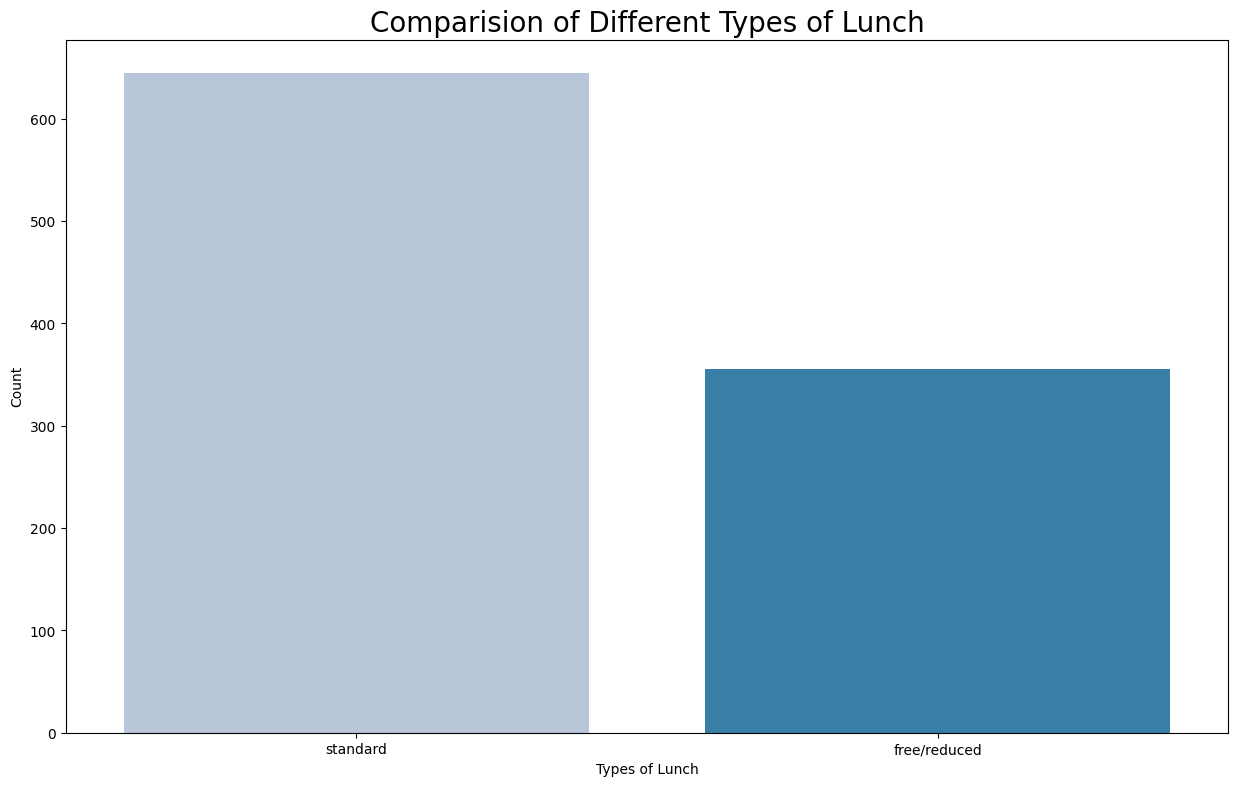

In [28]:
fig = plt.subplots(figsize=(15, 9))

sns.countplot(x=df['lunch'], palette='PuBu')
plt.title('Comparision of Different Types of Lunch', fontweight=30, fontsize=20)
plt.xlabel('Types of Lunch')
plt.ylabel('Count')

plt.show()

**INSIGHTS:**
- Students being served Standard Lunch was more than free lunch.

---
**--> BIVARIATE ANALYSIS (IS LUNCH TYPE INTAKE HAS ANY IMPACT ON STUDENT'S PERFORMANCE)**

Text(0.5, 1.0, 'Students vs Test Preparation Course')

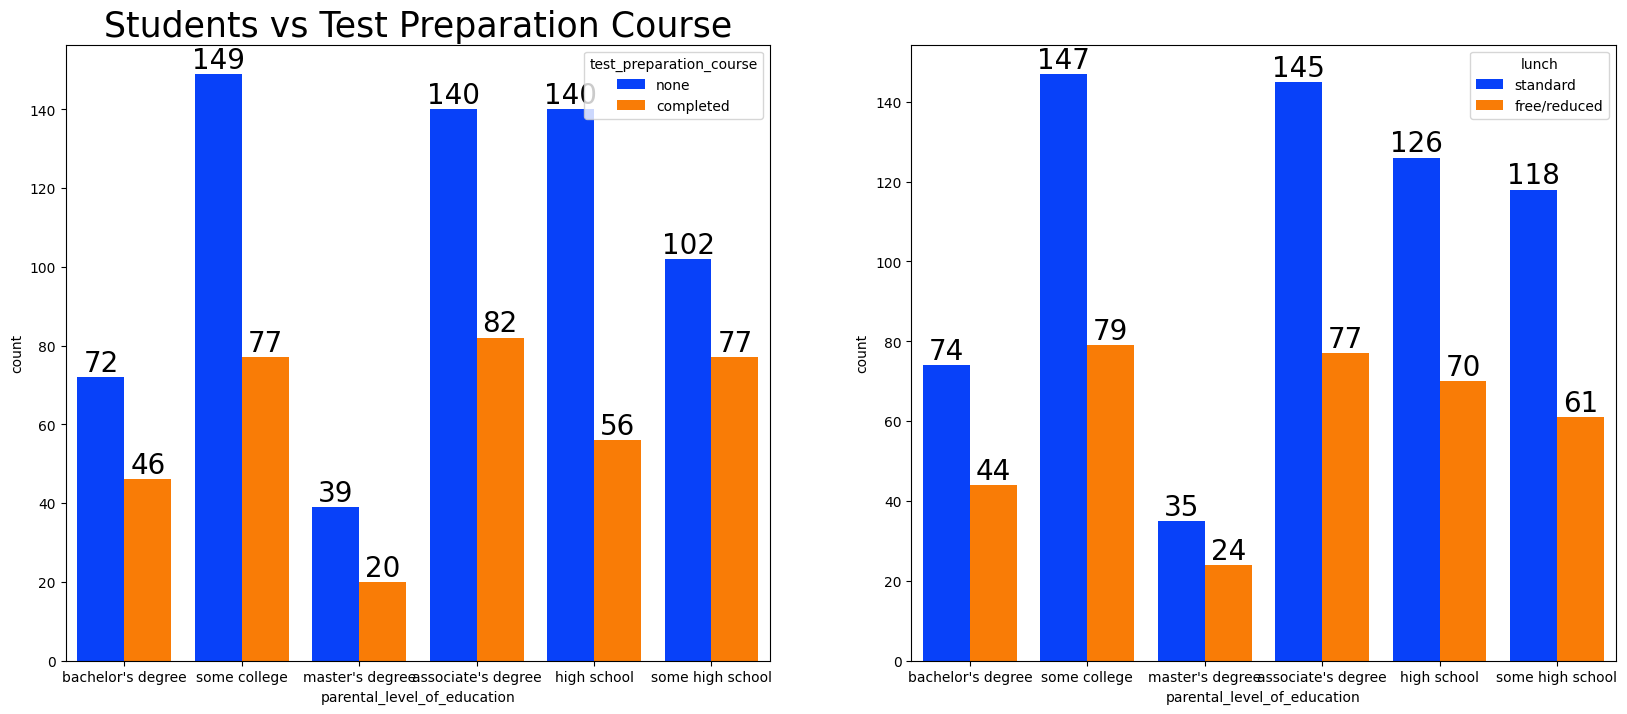

In [30]:
lunch_data = [
    ('parental_level_of_education', 'bright', 'test_preparation_course'),
    ('parental_level_of_education', 'bright', 'lunch'),
]
fig, axes = plt.subplots(1, len(lunch_data), figsize=(20, 8))

for ax, (column, palette, hue) in zip(axes, lunch_data):
    sns.countplot(
        data=df,
        x=column,
        palette=palette,
        hue=hue,
        saturation=0.95,
        ax=ax,
    )
    for container in ax.containers:
        ax.bar_label(container, color='black', size=20)

axes[0].set_title('Students vs Test Preparation Course', color='black', size=25)


**INSIGHTS:**
- Students who got Standard lunch tends to perform better than students who got Free / Reduced lunch.

---
### **TEST PREPARATION COURSE:**

- Which type of Lunch is most common among Students?
- Is Test Preparation course has any impact on Student's Performance?

**--> BIVARIATE ANALYSIS (IS TEST PREPARATION COURSE HAS ANY IMPACT ON STUDENTS PERFORMANCE)**

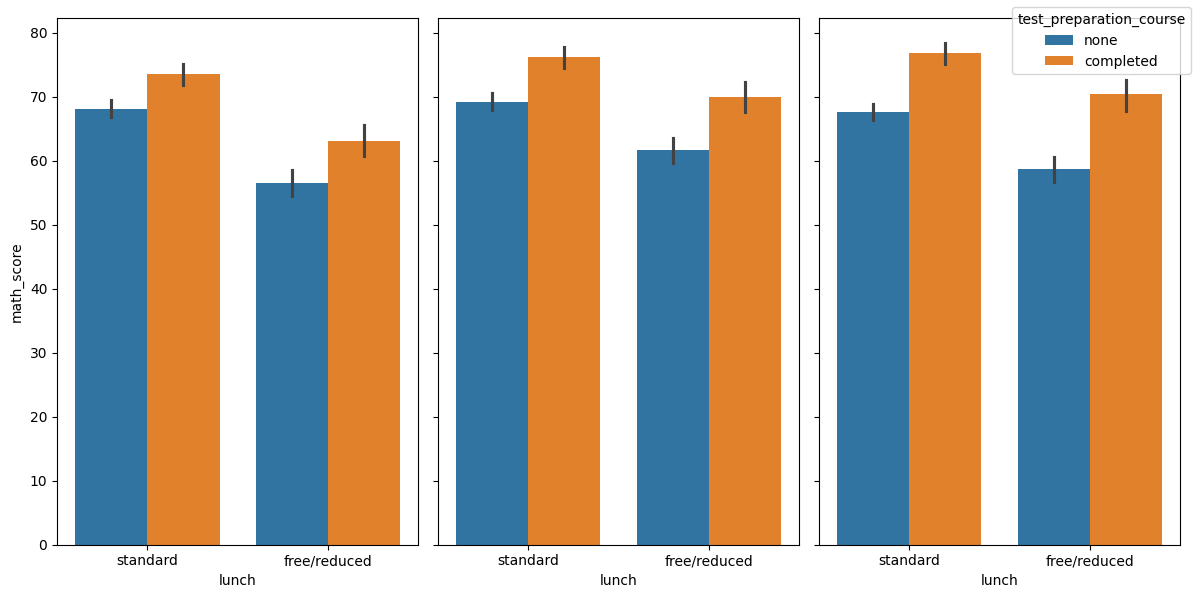

In [33]:
score_columns = ['math_score', 'reading_score', 'writing_score']
fig, axes = plt.subplots(1, len(score_columns), figsize = (12, 6), sharey = True)

for ax, score in zip(axes, score_columns):
    sns.barplot(
        data = df,
        x = 'lunch', y = score,
        hue = 'test_preparation_course',
        ax = ax,
    )

handles, labels = axes[0].get_legend_handles_labels()
for ax in axes:
    ax.get_legend().remove()

fig.legend(handles, labels, title = 'test_preparation_course')
plt.tight_layout()
plt.show()

**INSIGHTS:**
- Students who have completed the Test preparation courses have higher in all three categories than those who haven't taken the course.

---
**--> CHECKING OUTLIERS:**

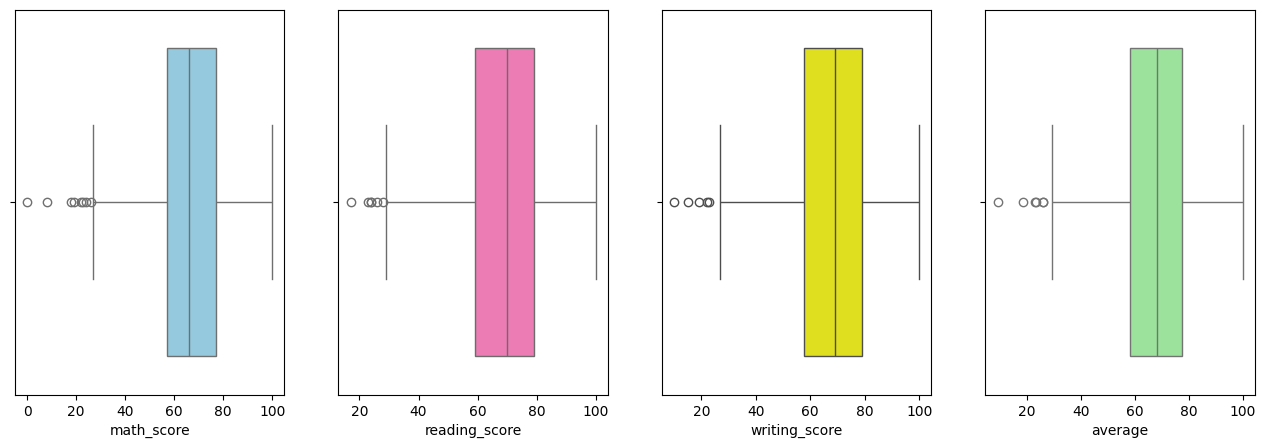

In [34]:
data = [
    ('math_score', 'skyblue'), ('reading_score', 'hotpink'),
    ('writing_score', 'yellow'), ('average', 'lightgreen')
]
fig, ax = plt.subplots(1, len(data), figsize = (16, 5))

for ax, (column, color) in zip(ax, data):
    sns.boxplot(
        data = df,
        x = column,
        color = color,
        ax = ax
    )
plt.show()

**INSIGHTS:**
- From the above plot it is clear that all scores increase linealy with each other.

---
### **CONCLUSIONS:**
- Student's Performance is related with Lunch, Race, Parental_level Education.
- Females lead in pass percentage and also are top-scorers.
- Student's performance is not much related with Test Performance Course.
- Finishing preparation course is beneficial.